## Task 3: Bounding Box and Split Axis

Median cut works by repeatedly splitting boxes in RGB space. Before a box can be split, we need to know two things: how much space its colors actually occupy, and along which channel it should be cut.

This step does both:

1. **Bounding box:** find the minimum and maximum value of each channel (R, G, B). This "shrinks" the box so that it fits tightly around the colors it contains, as described by Heckbert (1982).
2. **Split axis:** compute `range = max - min` for each channel and select the channel with the largest range.

**Why the longest axis?** The channel with the largest range is the direction in which the colors of the box differ the most. If the whole box were replaced by one representative color, most of the error would come from that direction, so cutting there reduces the error the most.

**Input:** an `(M, 3)` array of unique colors belonging to one box.
**Output:** the index of the axis to cut (0: Red, 1: Green, 2: Blue).

Only general NumPy tools are used (`min`, `max`, `argmax`).

In [1]:
import numpy as np

def bounding_box(colors):
    """
    Find the tightest box that encloses a set of colors.

    Input : colors -> array of shape (M, 3), one unique color [R, G, B] per row
    Output: (mins, maxs) -> minimum and maximum of each channel, both of shape (3,)
    """
    colors = np.asarray(colors)

    if colors.ndim != 2 or colors.shape[1] != 3:
        raise ValueError(f"Expected an array of shape (M, 3), got {colors.shape}")
    if colors.shape[0] == 0:
        raise ValueError("Cannot compute the bounding box of an empty color list.")

    # axis=0 goes down the rows, so each channel (column) is handled separately
    mins = colors.min(axis=0).astype(int)
    maxs = colors.max(axis=0).astype(int)
    return mins, maxs


def axis_ranges(colors):
    """Return the range (max - min) of each channel as an array of shape (3,)."""
    mins, maxs = bounding_box(colors)
    return maxs - mins


def find_split_axis(colors):
    """
    Select the axis with the largest range, along which the box will be cut.

    Input : colors -> array of shape (M, 3) with the unique colors of one box
    Output: 0 (Red), 1 (Green) or 2 (Blue)
    Note  : if two ranges are equal, the channel with the smaller index is chosen.
    """
    ranges = axis_ranges(colors)
    return int(np.argmax(ranges))

### Tests with known answers

Each test uses a small hand-made color list, so the correct result can be checked by eye.

- **Test 1:** green clearly has the largest range, so the answer must be 1.
- **Test 2:** red and blue have the same range. The paper does not say how to break ties, so we take the first channel (priority R, G, B).
- **Test 3:** a box with a single color has range 0 on every axis and cannot be split. The main loop (Task 5) can detect this case with `axis_ranges`.
- **Test 4:** image arrays are stored as `uint8`. The results are converted to `int` so that later arithmetic on them cannot wrap around.

In [3]:
# Test 1: green clearly has the largest range -> expect 1
test1 = np.array([[100, 30, 20],
                  [110, 220, 25],
                  [105, 120, 22]])
print("Bounding box:", bounding_box(test1))   # ([100, 30, 20], [110, 220, 25])
print("Ranges      :", axis_ranges(test1))    # [10, 190, 5]
assert find_split_axis(test1) == 1

# Test 2: tie between R and B -> first channel wins, expect 0
test2 = np.array([[0, 5, 0],
                  [50, 6, 50]])
assert find_split_axis(test2) == 0

# Test 3: single-color box -> all ranges are 0, the box cannot be split
test3 = np.array([[12, 7, 30]])
assert axis_ranges(test3).max() == 0

# Test 4: uint8 input must not overflow
test4 = np.array([[0, 0, 0], [255, 10, 10]], dtype=np.uint8)
assert axis_ranges(test4)[0] == 255

print("All tests passed.")

Bounding box: (array([100,  30,  20]), array([110, 220,  25]))
Ranges      : [ 10 190   5]
All tests passed.


### Test with mock data

Task 3 is developed independently of the other tasks, so here the function is run on random colors instead of a real histogram. Random colors are spread evenly over the cube, so the three ranges come out close to each other. This cell only shows that the function accepts the expected input shape; correctness is checked by the tests above.

In [5]:
rng = np.random.default_rng(42)
mock_colors = rng.integers(0, 256, size=(50, 3))

mins, maxs = bounding_box(mock_colors)
print("Min          :", mins)
print("Max          :", maxs)
print("Ranges       :", axis_ranges(mock_colors))
print("Selected axis:", find_split_axis(mock_colors), "(0: R, 1: G, 2: B)")

Min          : [20  1  7]
Max          : [254 229 251]
Ranges       : [234 228 244]
Selected axis: 2 (0: R, 1: G, 2: B)


### Visualization

Each color is drawn as a point in RGB space, in its own color. The gray lines are the bounding box and the red edges are parallel to the selected split axis. The example colors are generated with a narrow range in red and blue and a wide range in green, so the box is long in the green direction and green is selected.

For 15-bit data (values 0 to 31), call the function with `value_max=31` so that the points are colored correctly.

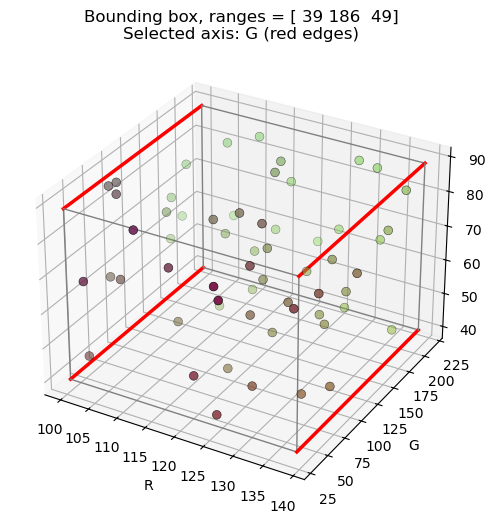

In [9]:
import matplotlib.pyplot as plt
from itertools import product

def plot_bounding_box(colors, value_max=255):
    """Draw the colors as points in RGB space with their bounding box and split axis."""
    colors = np.asarray(colors)
    mins, maxs = bounding_box(colors)
    axis = find_split_axis(colors)
    names = ["R", "G", "B"]

    fig = plt.figure(figsize=(7, 6))
    ax = fig.add_subplot(projection="3d")

    # Each point is drawn in its own color
    ax.scatter(colors[:, 0], colors[:, 1], colors[:, 2],
               c=colors / value_max, s=40, edgecolors="black", linewidths=0.4)

    # The 8 corners of the box: min or max for each channel
    corners = np.array(list(product(*zip(mins, maxs))))

    # Two corners that differ in exactly one coordinate form an edge (12 edges)
    for i in range(8):
        for j in range(i + 1, 8):
            diff = corners[i] != corners[j]
            if diff.sum() == 1:
                is_split_axis = diff[axis]
                ax.plot(*zip(corners[i], corners[j]),
                        color="red" if is_split_axis else "gray",
                        linewidth=2.5 if is_split_axis else 1)

    ax.set_xlabel("R"); ax.set_ylabel("G"); ax.set_zlabel("B")
    ax.set_title(f"Bounding box, ranges = {axis_ranges(colors)}\n"
                 f"Selected axis: {names[axis]} (red edges)")
    plt.show()


# Example color set that is spread widely along the green channel
rng = np.random.default_rng(0)
demo = np.column_stack([rng.integers(100, 140, 60),   # R: narrow
                        rng.integers(20, 230, 60),    # G: wide
                        rng.integers(40, 90, 60)])    # B: narrow
plot_bounding_box(demo)

### How this step connects to the rest

The main loop (Task 5) calls `find_split_axis` for the box it wants to split and passes the returned axis to Task 4, which sorts the colors along that axis and cuts at the weighted median. `axis_ranges` is also available to the main loop, for example to skip boxes that contain a single color.

The frequency weights from Task 2 are not used here: the bounding box depends only on which colors are present, not on how often they occur.